In [ ]:
# 1: Imports

In [ ]:
# 1.1 Imports

# Basis
import os
import numpy as np
import pandas as pd

# Audio
import librosa
import librosa.display

# Visualisierung
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn
from sklearn.model_selection import (
    StratifiedShuffleSplit,
    GroupKFold,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

import kagglehub
import os

# Anzeige von Audio
from IPython.display import Audio, display

# Warnings unterdrücken
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# 1.2 install Kagglehub
!pip install kagglehub

In [ ]:
# 1.3 import Datensatz Emodb, Speicherort path
import os

# Download latest version
path = kagglehub.dataset_download("piyushagni5/berlin-database-of-emotional-speech-emodb")

print("Path to dataset files:", path)

DATA_PATH = path

100%|██████████| 38.0M/38.0M [00:03<00:00, 11.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/piyushagni5/berlin-database-of-emotional-speech-emodb/versions/1


In [ ]:
# 1.4 Pfad & Dateien prüfen

print("Existiert Pfad?", os.path.exists(DATA_PATH))

files = os.listdir(DATA_PATH)
print("Ordnerinhalt:", files)

# Wenn nur ein Unterordner vorhanden ist -> wechseln
if len(files) == 1 and os.path.isdir(os.path.join(DATA_PATH, files[0])):
    DATA_PATH = os.path.join(DATA_PATH, files[0])
    print("Neuer DATA_PATH:", DATA_PATH)

files = os.listdir(DATA_PATH)
print("Anzahl WAV-Dateien:", len(files))
print("Beispiel-Dateien:", files[:5])

Existiert Pfad? True
Ordnerinhalt: ['wav']
Neuer DATA_PATH: /root/.cache/kagglehub/datasets/piyushagni5/berlin-database-of-emotional-speech-emodb/versions/1/wav
Anzahl WAV-Dateien: 535
Beispiel-Dateien: ['11b01Lb.wav', '09a02La.wav', '10b10Fc.wav', '09b02Wd.wav', '13b02Nb.wav']


In [ ]:
# 2.1 EMODB DataFrame erstellen

emotion_map = {
    'W': 'anger',
    'L': 'boredom',
    'E': 'disgust',
    'A': 'fear',
    'F': 'happiness',
    'T': 'sadness',
    'N': 'neutral'
}

rows = []

# Nur WAV-Dateien aus dem echten DATA_PATH
files = [f for f in os.listdir(DATA_PATH) if f.endswith(".wav")]

for file in files:

    speaker_id = file[0:2]
    sentence_id = file[3:5]
    emotion_code = file[5].upper()
    repetition = file[6]

    rows.append({
        "file": file,
        "path": os.path.join(DATA_PATH, file),   # DATA_PATH verwenden
        "speaker_id": speaker_id,
        "sentence_id": sentence_id,
        "emotion_code": emotion_code,
        "emotion": emotion_map.get(emotion_code, "unknown"),
        "repetition": repetition
    })

dataframe_emodb = pd.DataFrame(rows)

print("Anzahl Einträge:", len(dataframe_emodb))
dataframe_emodb.head()

Anzahl Einträge: 535


,file,path,speaker_id,sentence_id,emotion_code,emotion,repetition
0,11b01Lb.wav,/root/.cache/kagglehub/datasets/piyushagni5/be...,11,01,L,boredom,b
1,09a02La.wav,/root/.cache/kagglehub/datasets/piyushagni5/be...,09,02,L,boredom,a
2,10b10Fc.wav,/root/.cache/kagglehub/datasets/piyushagni5/be...,10,10,F,happiness,c
3,09b02Wd.wav,/root/.cache/kagglehub/datasets/piyushagni5/be...,09,02,W,anger,d
4,13b02Nb.wav,/root/.cache/kagglehub/datasets/piyushagni5/be...,13,02,N,neutral,b


In [ ]:
# 2.2 Anzahl Elemente
len(dataframe_emodb)

535

In [ ]:
# 2.3 Emotionsverteilung
dataframe_emodb['emotion'].value_counts()

,count
emotion,
anger,127
boredom,81
neutral,79
happiness,71
fear,69
sadness,62
disgust,46



Emotion: anger
Datei: /root/.cache/kagglehub/datasets/piyushagni5/berlin-database-of-emotional-speech-emodb/versions/1/wav/11b09Wa.wav


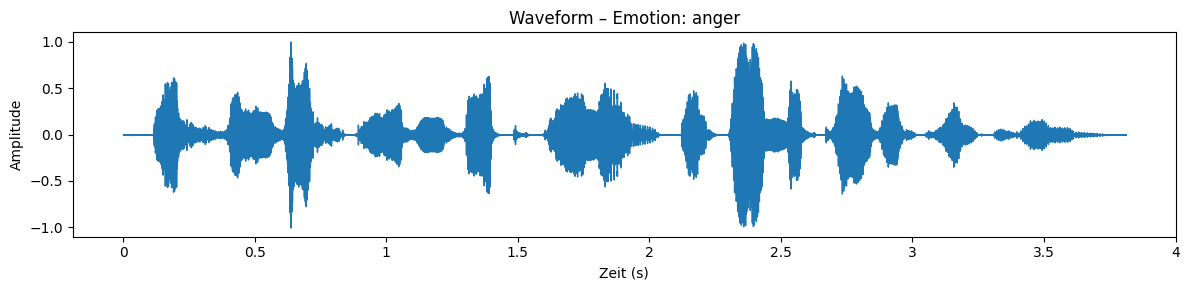

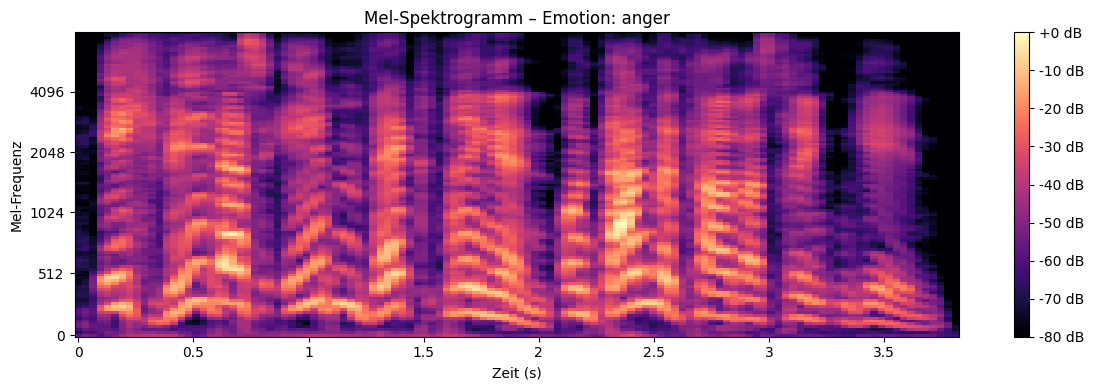


Emotion: boredom
Datei: /root/.cache/kagglehub/datasets/piyushagni5/berlin-database-of-emotional-speech-emodb/versions/1/wav/10a07La.wav


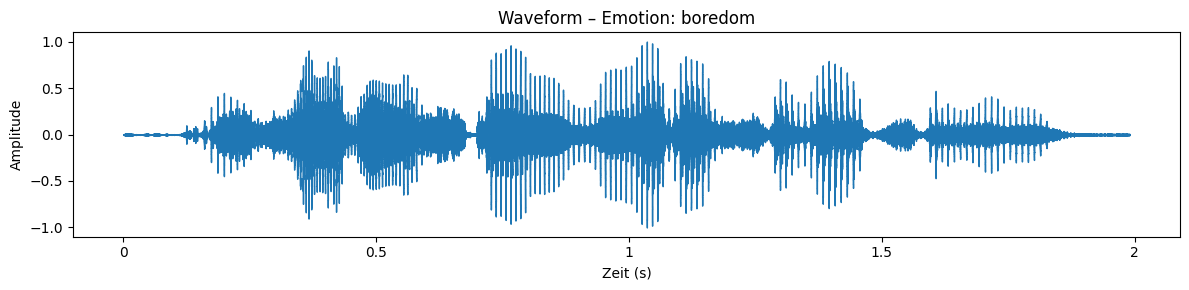

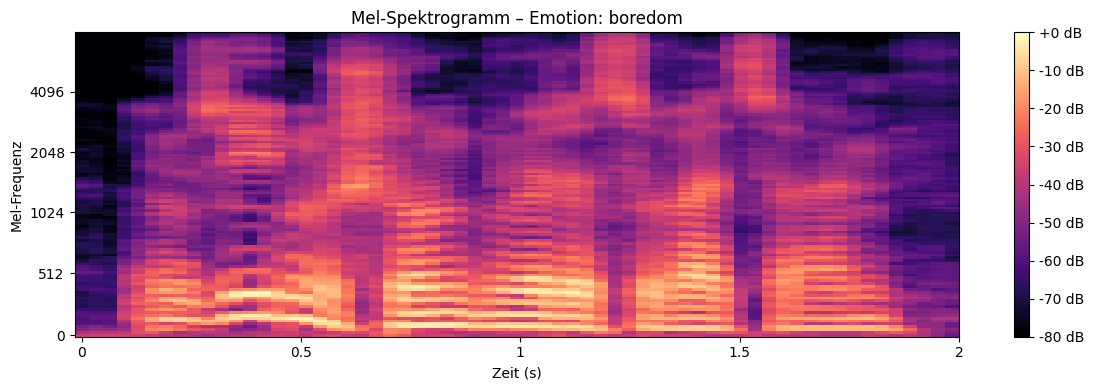


Emotion: disgust
Datei: /root/.cache/kagglehub/datasets/piyushagni5/berlin-database-of-emotional-speech-emodb/versions/1/wav/09b01Ea.wav


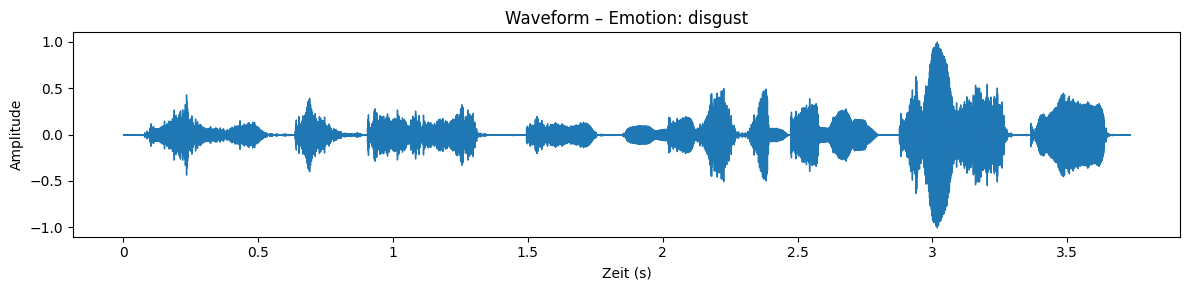

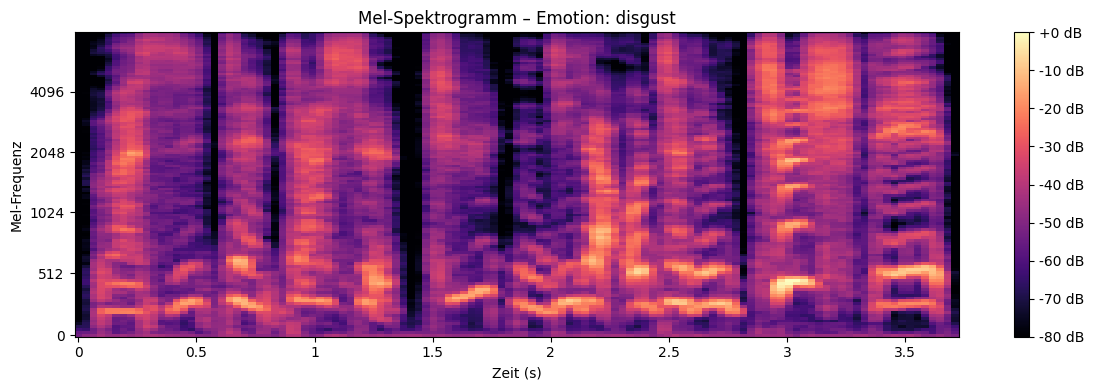


Emotion: fear
Datei: /root/.cache/kagglehub/datasets/piyushagni5/berlin-database-of-emotional-speech-emodb/versions/1/wav/15b02Aa.wav


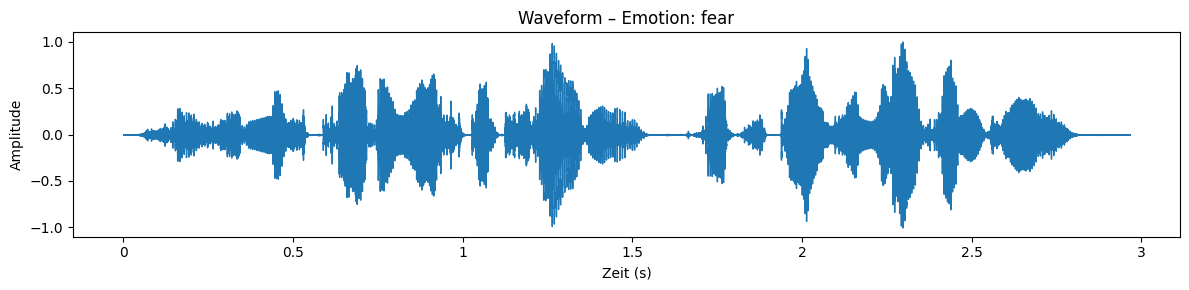

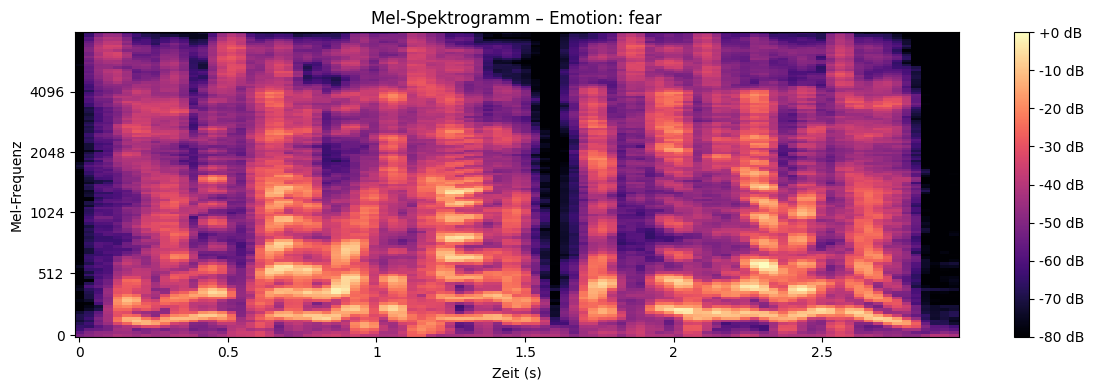


Emotion: happiness
Datei: /root/.cache/kagglehub/datasets/piyushagni5/berlin-database-of-emotional-speech-emodb/versions/1/wav/16a05Fc.wav


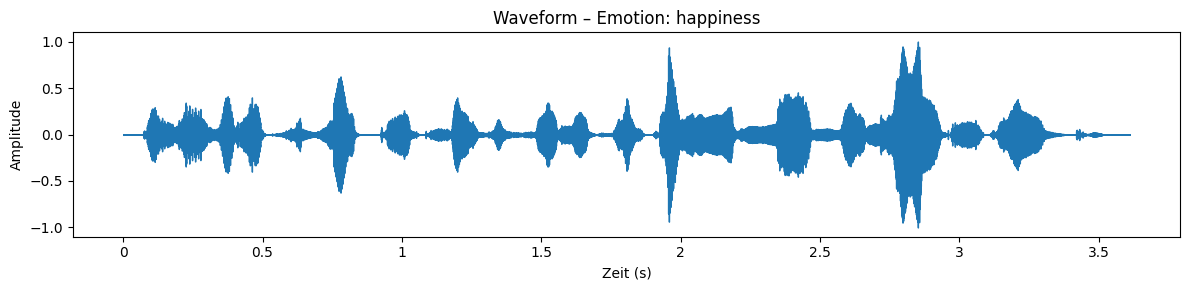

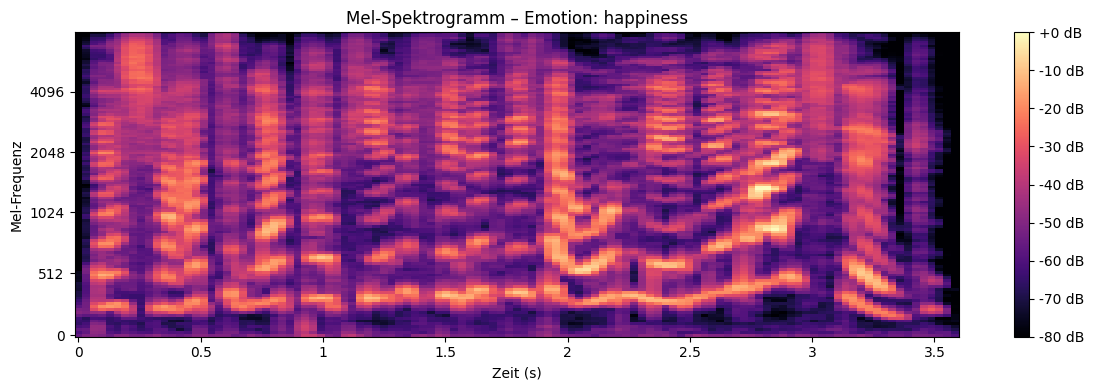


Emotion: neutral
Datei: /root/.cache/kagglehub/datasets/piyushagni5/berlin-database-of-emotional-speech-emodb/versions/1/wav/12a02Nb.wav


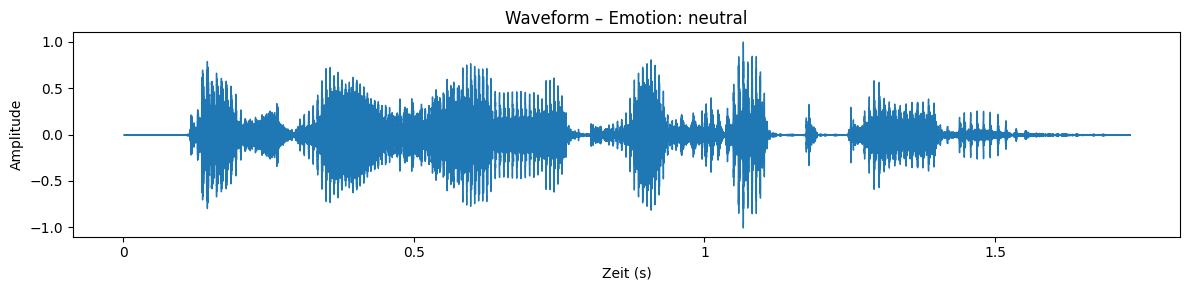

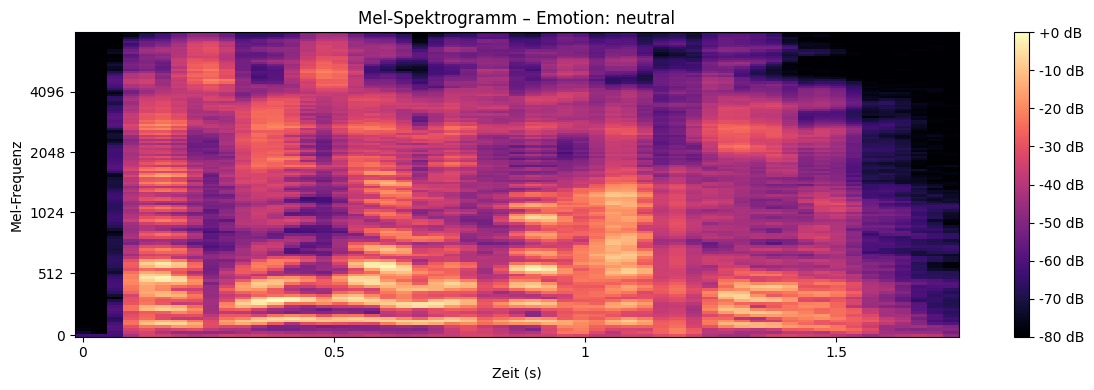


Emotion: sadness
Datei: /root/.cache/kagglehub/datasets/piyushagni5/berlin-database-of-emotional-speech-emodb/versions/1/wav/08a07Ta.wav


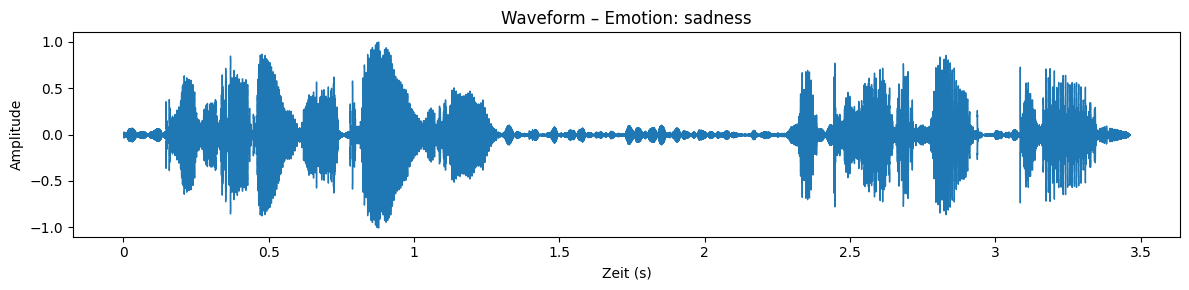

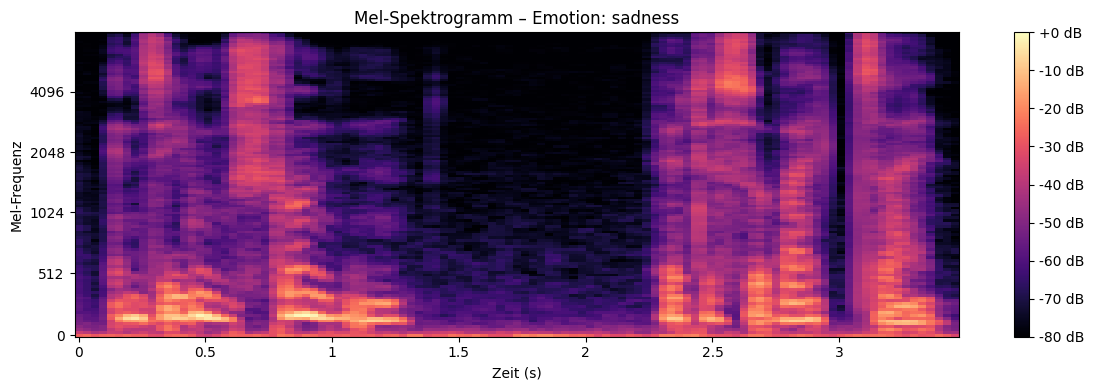

In [ ]:
# 2.4
#Stichprobe Wave Diagramm, Mel-Spektrogramm, Audio pro Emotion
#Stichprobe: 1 Beispiel pro Emotion

SR = 16000
N_MELS = 128
RANDOM_STATE = 42

# Sicherheitscheck
required_cols = {"path", "emotion"}
missing = required_cols - set(dataframe_emodb.columns)
if missing:
    raise ValueError(f"dataframe_emodb fehlt Spalten: {missing}")

emotions = sorted(dataframe_emodb["emotion"].unique())

for emotion in emotions:
    print("\n" + "=" * 90)
    print(f"Emotion: {emotion}")

    subset = dataframe_emodb[dataframe_emodb["emotion"] == emotion]
    if subset.empty:
        print(f"Kein Beispiel gefunden für Emotion '{emotion}'")
        continue

    # 1 zufällige Datei pro Emotion
    row = subset.sample(1, random_state=RANDOM_STATE).iloc[0]
    fp = row["path"]

    print(f"Datei: {fp}")

    # Audio laden
    y, sr = librosa.load(fp, sr=SR, mono=True)

    # Audio abspielen
    display(Audio(y, rate=sr))

    # Waveform
    plt.figure(figsize=(12, 3))
    librosa.display.waveshow(y, sr=sr)
    plt.title(f"Waveform – Emotion: {emotion}")
    plt.xlabel("Zeit (s)")
    plt.ylabel("Amplitude")
    plt.tight_layout()
    plt.show()

    # Mel-Spektrogramm
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=N_MELS)
    S_db = librosa.power_to_db(S, ref=np.max)

    plt.figure(figsize=(12, 4))
    librosa.display.specshow(S_db, sr=sr, x_axis="time", y_axis="mel")
    plt.colorbar(format="%+2.0f dB")
    plt.title(f"Mel-Spektrogramm – Emotion: {emotion}")
    plt.xlabel("Zeit (s)")
    plt.ylabel("Mel-Frequenz")
    plt.tight_layout()
    plt.show()


In [ ]:
# 3 --- DATENVORVERARBEITUNG ---

Keine unbekannten Emotionslabels gefunden (keine 'unknown'-Einträge).


,file,path,emotion
0,11b01Lb.wav,/root/.cache/kagglehub/datasets/piyushagni5/be...,boredom
1,09a02La.wav,/root/.cache/kagglehub/datasets/piyushagni5/be...,boredom
2,10b10Fc.wav,/root/.cache/kagglehub/datasets/piyushagni5/be...,happiness
3,09b02Wd.wav,/root/.cache/kagglehub/datasets/piyushagni5/be...,anger
4,13b02Nb.wav,/root/.cache/kagglehub/datasets/piyushagni5/be...,neutral


Alle Audiodateien sind vorhanden und korrekt zugeordnet.


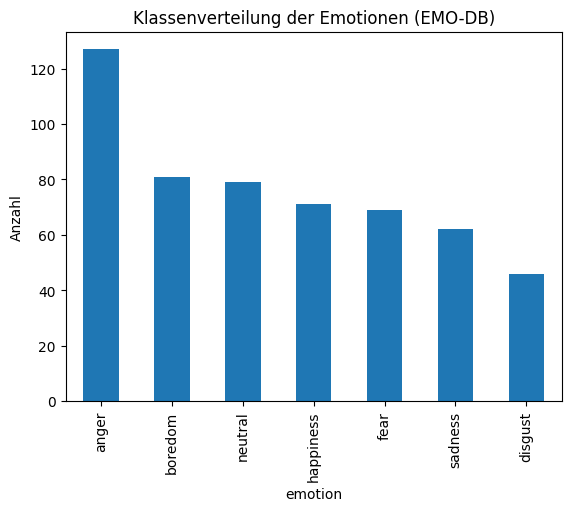

In [ ]:
# 3.1	Label- und Metadatenprüfung

#Überprüfung der Emotionslabels (keine unknown-Einträge)
(dataframe_emodb["emotion"] == "unknown").sum()
unknown_count = (dataframe_emodb["emotion"] == "unknown").sum()

if unknown_count == 0:
    print("Keine unbekannten Emotionslabels gefunden (keine 'unknown'-Einträge).")
else:
    print(f"Achtung: {unknown_count} unbekannte Emotionslabels ('unknown') gefunden.")

#Kontrolle der Zuordnung zwischen Audiodateien und Labels
display(dataframe_emodb[["file", "path", "emotion"]].head())

all_exist = dataframe_emodb["path"].apply(os.path.exists).all()
if all_exist:
    print("Alle Audiodateien sind vorhanden und korrekt zugeordnet.")
else:
    print("Fehler: Nicht alle Audiodateien konnten gefunden werden.")


#Analyse der Klassenverteilung
dataframe_emodb["emotion"].value_counts()

dataframe_emodb["emotion"].value_counts().plot(kind="bar")
plt.title("Klassenverteilung der Emotionen (EMO-DB)")
plt.ylabel("Anzahl")
plt.show()


In [ ]:
#	Einheitliche Audio-Basis herstellen

In [ ]:
# 3.2	Beibehaltung der nativen Abtastrate (16 kHz)
import librosa
import numpy as np

sr_list = []
readable_flags = []

for path in dataframe_emodb["path"]:
    try:
        # sr=None -> native Abtastrate, kein Resampling
        _, sr = librosa.load(path, sr=None)
        sr_list.append(sr)
        readable_flags.append(True)
    except Exception:
        sr_list.append(np.nan)
        readable_flags.append(False)

dataframe_emodb["readable"] = readable_flags
dataframe_emodb["sampling_rate"] = sr_list

# Übersicht
print("Lesbarkeit der Dateien:")
print(dataframe_emodb["readable"].value_counts(dropna=False))

print("\nEinzigartige Abtastraten im Datensatz:")
print(sorted(dataframe_emodb.loc[dataframe_emodb["readable"], "sampling_rate"].unique()))

# Explizite Prüfung auf Abweichungen von 16 kHz
TARGET_SR = 16000

abweichende_sr = dataframe_emodb.loc[
    dataframe_emodb["readable"] & (dataframe_emodb["sampling_rate"] != TARGET_SR),
    ["file", "sampling_rate"]
]

print("\nDateien mit abweichender Abtastrate:", len(abweichende_sr))
abweichende_sr.head()


Lesbarkeit der Dateien:
readable
True    535
Name: count, dtype: int64

Einzigartige Abtastraten im Datensatz:
[np.int64(16000)]

Dateien mit abweichender Abtastrate: 0


,file,sampling_rate


In [ ]:
# 3.3	Sicherstellung des Mono-Formats

import librosa
import numpy as np

n_channels_list = []

for path in dataframe_emodb["path"]:
    try:
        # mono=False -> Originalkanäle beibehalten
        y, _ = librosa.load(path, sr=None, mono=False)

        # y ist entweder samples bei mono
        # oder channels, samples bei stereo
        if y.ndim == 1:
            n_channels_list.append(1)
        else:
            n_channels_list.append(y.shape[0])

    except Exception:
        n_channels_list.append(np.nan)

dataframe_emodb["n_channels"] = n_channels_list

print("Kanalanzahl (Value Counts):")
print(dataframe_emodb["n_channels"].value_counts(dropna=False))

mehrkanal = dataframe_emodb.loc[dataframe_emodb["n_channels"] > 1, ["file", "n_channels"]]
print("\nMehrkanal-Dateien:", len(mehrkanal))
mehrkanal.head()


Kanalanzahl (Value Counts):
n_channels
1    535
Name: count, dtype: int64

Mehrkanal-Dateien: 0


,file,n_channels


In [ ]:
# 3.4	Prüfung der Audiodateien auf Lesbarkeit und Mindestlänge
readable_flags = []

for path in dataframe_emodb["path"]:
    try:
        # Versuch, die Audiodatei zu laden
        librosa.load(path, sr=None)
        readable_flags.append(True)
    except Exception:
        readable_flags.append(False)

dataframe_emodb["readable"] = readable_flags

print("Lesbarkeit der Audiodateien:")
print(dataframe_emodb["readable"].value_counts(dropna=False))

# Liste nicht-lesbarer Dateien anzeigen
unreadable_files = dataframe_emodb.loc[~dataframe_emodb["readable"], ["file", "path"]]
print("\nNicht lesbare Dateien:", len(unreadable_files))
unreadable_files.head()

#Mindestlänge
import librosa
import numpy as np

MIN_DURATION_SEC = 0.5

durations = []

for path in dataframe_emodb["path"]:
    try:
        # mono=False, damit unabhängig von Kanalanzahl korrekt gezählt wird
        y, sr = librosa.load(path, sr=None, mono=False)

        if y.ndim == 1:
            n_samples = len(y)
        else:
            n_samples = y.shape[1]  # (channels, samples)

        durations.append(n_samples / sr)

    except Exception:
        durations.append(np.nan)

dataframe_emodb["duration_sec"] = durations

# Statistik
print("Dauerstatistik (Sekunden):")
print(dataframe_emodb["duration_sec"].describe())

# Prüfung auf zu kurze Dateien
too_short = dataframe_emodb.loc[
    dataframe_emodb["duration_sec"] < MIN_DURATION_SEC,
    ["file", "duration_sec"]
]

print(f"\nAudiodateien kürzer als {MIN_DURATION_SEC} Sekunden:", len(too_short))
too_short.head()


Lesbarkeit der Audiodateien:
readable
True    535
Name: count, dtype: int64

Nicht lesbare Dateien: 0
Dauerstatistik (Sekunden):
count    535.000000
mean       2.779612
std        1.028189
min        1.225500
25%        2.026594
50%        2.590187
75%        3.308406
max        8.978250
Name: duration_sec, dtype: float64

Audiodateien kürzer als 0.5 Sekunden: 0


,file,duration_sec


In [ ]:
# Akustische Bereinigung

In [ ]:
# 3.5 Festlegung fester Trimm-Parameter
TRIM_TOP_DB = 20
TRIM_FRAME_LENGTH = 2048
TRIM_HOP_LENGTH = 512

In [ ]:
# 3.6 Entfernung von Stille am Anfang und Ende der Aufnahmen

import librosa

# Audio laden
y, sr = librosa.load(path, sr=None)

#Trimmen
y_trimmed, idx = librosa.effects.trim(
    y,
    top_db=TRIM_TOP_DB,
    frame_length=TRIM_FRAME_LENGTH,
    hop_length=TRIM_HOP_LENGTH
)

start_sample, end_sample = idx

# Dauervergleich
dur_before = len(y) / sr
dur_after  = len(y_trimmed) / sr

print(f"Start-Sample entfernt: {start_sample}")
print(f"End-Sample entfernt bis: {end_sample} von {len(y)}")
print(f"Dauer vorher: {dur_before:.2f}s")
print(f"Dauer nachher: {dur_after:.2f}s")
print(f"Entfernte Randstille: {dur_before - dur_after:.2f}s")


Start-Sample entfernt: 2048
End-Sample entfernt bis: 26624 von 27771
Dauer vorher: 1.74s
Dauer nachher: 1.54s
Entfernte Randstille: 0.20s


In [ ]:
# 3.7 Anwendung identischer Parameter auf Trainings-, Validierungs- und Testdaten
# Einheitliche Lade- und Trimmfunktion für Trainings-, Validierungs- und Testdaten
import librosa

def load_and_trim_audio(path):


    y, sr = librosa.load(path, sr=None)

    # Trimmen mit definierten Parametern
    y, _ = librosa.effects.trim(
        y,
        top_db=TRIM_TOP_DB,
        frame_length=TRIM_FRAME_LENGTH,
        hop_length=TRIM_HOP_LENGTH
    )

    return y, sr


In [ ]:
# --- Normalisierung der Audiosignale ---

In [ ]:
# 3.8 Auswahl der Normalisierungsstrategie (Amplitude)
NORMALIZATION_METHOD = "peak"

In [ ]:
# 3.9 Verwendung fester Normalisierungsregeln
import numpy as np

def peak_normalize(y):
    peak = np.max(np.abs(y))
    if peak > 0:
        y = y / peak
    return y


In [ ]:
# 3.10 Anwendung identischer Regeln auf Trainings-, Validierungs- und Testdaten
# Einheitliche Vorverarbeitung für alle Datensplits:

#Laden
def load_preprocessed_audio(path):

    y, sr = librosa.load(path, sr=None)

    #Trimmen
    y, _ = librosa.effects.trim(
        y,
        top_db=TRIM_TOP_DB,
        frame_length=TRIM_FRAME_LENGTH,
        hop_length=TRIM_HOP_LENGTH
    )

    # Amplituden-Normalisierung
    y = peak_normalize(y)

    # Mindestlänge für stabile FFT sicherstellen
    MIN_LEN = 2048
    if len(y) < MIN_LEN:
        y = np.pad(y, (0, MIN_LEN - len(y)))

    return y, sr


In [ ]:
# --- 4	Feature-Extraktion ---

In [ ]:
# 4.1	Gemeinsame Parameter
import numpy as np
import librosa

# Frame-/STFT-Parameter
N_FFT = 2048
HOP_LENGTH = 512
WIN_LENGTH = 2048


In [ ]:
# 4.2	MFCC (Mel-Frequency Cepstral Coefficients)
N_MFCC = 13

mfcc = librosa.feature.mfcc(
    y=y,
    sr=sr,
    n_mfcc=N_MFCC,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH
)  # shape: (n_mfcc, frames)


In [ ]:
# 4.3 RMS-Energie
# Berechnung der Root Mean Square (RMS)-Energie als Maß für die durchschnittliche Signalstärke eines Audiosignals pro Frame

rms = librosa.feature.rms(
    y=y,
    frame_length=N_FFT,
    hop_length=HOP_LENGTH,
    center=True
)  # shape: (1, frames)


# Logarithmische Skalierung (Lautstärke in dB)
# Transformation der RMS-Werte in eine logarithmische Skala (Dezibel) um Lautstärke des Signals abzubilden

rms_db = librosa.amplitude_to_db(
    rms,
    ref=np.max
)  # shape: (1, frames)

In [ ]:
# 4.4	Zero-Crossing Rate (ZCR)
zcr = librosa.feature.zero_crossing_rate(
    y,
    frame_length=N_FFT,
    hop_length=HOP_LENGTH,
    center=True
)  # shape: (1, frames)


In [ ]:
# 4.5	Pitch (Grundfrequenz)
fmin = 50   # Untergrenze Sprache
fmax = 400  # Obergrenze Sprache

pitch_hz = librosa.yin(
    y=y,
    fmin=fmin,
    fmax=fmax,
    sr=sr,
    frame_length=N_FFT,
    hop_length=HOP_LENGTH
)  # shape: (frames,)



In [ ]:
# 4.6 Unvoiced Frames maskieren
pitch_hz_masked = np.where(np.isfinite(pitch_hz), pitch_hz, np.nan)

In [ ]:
# 4.8	Spektraler Schwerpunkt (Spectral Centroi)
spec_centroid = librosa.feature.spectral_centroid(
    y=y,
    sr=sr,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH
)  # shape: (1, frames)


In [ ]:
# 4.9 Spektrale Bandbreite (Spectral Bandwidth)
spec_bandwidth = librosa.feature.spectral_bandwidth(
    y=y,
    sr=sr,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH
)  # shape: (1, frames)


In [ ]:
# 4.10 Chroma-Features
chroma = librosa.feature.chroma_stft(
    y=y,
    sr=sr,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH
)  # shape: (12, frames)


In [ ]:
# 4.11 Spektraler Kontrast
spec_contrast = librosa.feature.spectral_contrast(
    y=y,
    sr=sr,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH
)  # shape: (7, frames) typischerweise


In [ ]:
# 4.12 Tonnetz
tonnetz = librosa.feature.tonnetz(
    y=y,
    sr=sr
)  # shape: (6, frames)


In [ ]:
# ---	Aggregation ---

In [ ]:
# 4.14 Mittelwert
import numpy as np

def stat_mean(x):
    return np.nanmean(x)


In [ ]:
# 4.15 Standardabweichung
def stat_std(x):
    return np.nanstd(x)


In [ ]:
# 4.16 Minimum
def stat_min(x):
    return np.nanmin(x)


In [ ]:
# 4.17 Maximum
def stat_max(x):
    return np.nanmax(x)


In [ ]:
# 4.18 Aggregation aller zeitabhängigen Merkmale zu einem festen 1D Feature-Vektor pro Audiodatei
def aggregate_llds(feats, use_minmax=True):

    feature_vector = {}

    for name, arr in feats.items():
        arr = np.asarray(arr)

        # 1D-Features: (frames,)
        if arr.ndim == 1:
            feature_vector[f"{name}_mean"] = np.nanmean(arr)
            feature_vector[f"{name}_std"]  = np.nanstd(arr)
            if use_minmax:
                feature_vector[f"{name}_min"] = np.nanmin(arr)
                feature_vector[f"{name}_max"] = np.nanmax(arr)

        # 2D-Features: (dims, frames)
        elif arr.ndim == 2:
            for i in range(arr.shape[0]):
                x = arr[i, :]
                feature_vector[f"{name}_{i:02d}_mean"] = np.nanmean(x)
                feature_vector[f"{name}_{i:02d}_std"]  = np.nanstd(x)
                if use_minmax:
                    feature_vector[f"{name}_{i:02d}_min"] = np.nanmin(x)
                    feature_vector[f"{name}_{i:02d}_max"] = np.nanmax(x)

    return feature_vector


In [ ]:
# --- 5	Feature-Skalierung --- 6	Aufteilung in Trainings-, Validierungs- und Testdaten ---

In [ ]:
# 5.1 Feature Extrahierung

import numpy as np
import librosa

def extract_llds(y, sr):

    feats = {}

    # MFCC
    mfcc = librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=N_MFCC,
        n_fft=N_FFT, hop_length=HOP_LENGTH, win_length=WIN_LENGTH
    )
    feats["mfcc"] = mfcc

    # RMS
    rms = librosa.feature.rms(
        y=y, frame_length=N_FFT, hop_length=HOP_LENGTH, center=True
    )
    feats["rms"] = rms

    # ZCR
    zcr = librosa.feature.zero_crossing_rate(
        y, frame_length=N_FFT, hop_length=HOP_LENGTH, center=True
    )
    feats["zcr"] = zcr

    # Pitch
    try:
        pitch_hz = librosa.yin(
            y=y, fmin=50, fmax=400, sr=sr,
            frame_length=N_FFT, hop_length=HOP_LENGTH
        )  # (frames,)
        pitch_hz_masked = np.where(np.isfinite(pitch_hz), pitch_hz, np.nan)
        feats["pitch_hz"] = pitch_hz_masked
    except Exception:

        pass

    # RMS dB
    try:
        rms_db = librosa.amplitude_to_db(rms, ref=np.max)  # (1, frames)
        feats["rms_db"] = rms_db
    except Exception:
        pass

    # Spectral Centroid
    feats["spec_centroid"] = librosa.feature.spectral_centroid(
        y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, win_length=WIN_LENGTH
    )

    # Spectral Bandwidth
    feats["spec_bandwidth"] = librosa.feature.spectral_bandwidth(
        y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, win_length=WIN_LENGTH
    )

    # Chroma
    feats["chroma"] = librosa.feature.chroma_stft(
        y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

    # Spectral Contrast
    feats["spec_contrast"] = librosa.feature.spectral_contrast(
        y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

    # Tonnetz
    try:
        feats["tonnetz"] = librosa.feature.tonnetz(y=y, sr=sr)
    except Exception:
        pass

    return feats

In [ ]:
# 5.2 : features_df erstellen

rows = []

for _, r in dataframe_emodb.iterrows():
    y, sr = load_preprocessed_audio(r["path"])
    feats = extract_llds(y, sr)
    vec = aggregate_llds(feats, use_minmax=True)

    vec["emotion"] = r["emotion"]
    vec["speaker_id"] = r["speaker_id"]
    vec["file"] = r["file"]
    vec["path"] = r["path"]

    rows.append(vec)

features_df = pd.DataFrame(rows)

print(features_df.shape)

(535, 180)


In [ ]:
# 6.1 LOSO (GroupKFold)

from sklearn.model_selection import GroupKFold

X = features_df.drop(columns=["emotion", "speaker_id", "file", "path"], errors="ignore")
y = features_df["emotion"]
groups = features_df["speaker_id"]  # <- wichtig: Länge 535

print("Shapes:", X.shape, y.shape, groups.shape)  # Debug

gkf = GroupKFold(n_splits=groups.nunique())
print("Anzahl Sprecher (Folds):", groups.nunique())

Shapes: (535, 176) (535,) (535,)
Anzahl Sprecher (Folds): 10


In [ ]:
#5.3  Feature-Check welche Features im Modell enthalten sind (zur Kontrolle)

META_COLS = ["emotion", "speaker_id", "file", "path"]
feature_cols = [c for c in features_df.columns if c not in META_COLS]

#Feature Gruppen
groups = {
    "MFCC": [],
    "RMS": [],
    "ZCR": [],
    "Pitch": [],
    "Spectral": [],
    "Chroma": [],
    "Tonnetz": [],
    "Andere": []
}

#Einordnen
for c in feature_cols:
    lc = c.lower()
    if "mfcc" in lc:
        groups["MFCC"].append(c)
    elif "rms" in lc:
        groups["RMS"].append(c)
    elif "zcr" in lc:
        groups["ZCR"].append(c)
    elif "pitch" in lc:
        groups["Pitch"].append(c)
    elif any(k in lc for k in ["centroid","bandwidth","contrast"]):
        groups["Spectral"].append(c)
    elif "chroma" in lc:
        groups["Chroma"].append(c)
    elif "tonnetz" in lc:
        groups["Tonnetz"].append(c)
    else:
        groups["Andere"].append(c)

#Ausgabe
print("ANZAHL FEATURES IM MODELL:", len(feature_cols))

for k,v in groups.items():
    print(f"{k:10s}: {len(v)}")

print("\n--- KOMPLETTE FEATURELISTE ---")
for f in feature_cols:
    print(f)


ANZAHL FEATURES IM MODELL: 176
MFCC      : 52
RMS       : 8
ZCR       : 4
Pitch     : 4
Spectral  : 36
Chroma    : 48
Tonnetz   : 24
Andere    : 0

--- KOMPLETTE FEATURELISTE ---
mfcc_00_mean
mfcc_00_std
mfcc_00_min
mfcc_00_max
mfcc_01_mean
mfcc_01_std
mfcc_01_min
mfcc_01_max
mfcc_02_mean
mfcc_02_std
mfcc_02_min
mfcc_02_max
mfcc_03_mean
mfcc_03_std
mfcc_03_min
mfcc_03_max
mfcc_04_mean
mfcc_04_std
mfcc_04_min
mfcc_04_max
mfcc_05_mean
mfcc_05_std
mfcc_05_min
mfcc_05_max
mfcc_06_mean
mfcc_06_std
mfcc_06_min
mfcc_06_max
mfcc_07_mean
mfcc_07_std
mfcc_07_min
mfcc_07_max
mfcc_08_mean
mfcc_08_std
mfcc_08_min
mfcc_08_max
mfcc_09_mean
mfcc_09_std
mfcc_09_min
mfcc_09_max
mfcc_10_mean
mfcc_10_std
mfcc_10_min
mfcc_10_max
mfcc_11_mean
mfcc_11_std
mfcc_11_min
mfcc_11_max
mfcc_12_mean
mfcc_12_std
mfcc_12_min
mfcc_12_max
rms_00_mean
rms_00_std
rms_00_min
rms_00_max
zcr_00_mean
zcr_00_std
zcr_00_min
zcr_00_max
pitch_hz_mean
pitch_hz_std
pitch_hz_min
pitch_hz_max
rms_db_00_mean
rms_db_00_std
rms_db_00_mi

In [ ]:
# --- 7	Training der SVM (Baseline) ---

In [ ]:
# SVM Echtzeit - Extra Features - Sprecherunabhängig - LOSO RUN

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    matthews_corrcoef,
    precision_recall_fscore_support
)

# Basisdaten
X = features_df.drop(columns=["emotion", "speaker_id", "file", "path"], errors="ignore")
y = features_df["emotion"]
groups = features_df["speaker_id"]

labels = sorted(y.unique())

print("DEBUG Shapes:", X.shape, y.shape, groups.shape)
print("Unique speakers:", groups.nunique())


# Outer CV (LOSO)
# Ein Speaker wird komplett rausgenommen , Speaker 1 wird für TEST verwendet, alle anderen für TRAIN
outer_cv = GroupKFold(n_splits=groups.nunique())

# Inner CV (nur auf Trainingsdaten jedes Folds)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Pipeline
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", class_weight=None, random_state=42)) #None -> kein Klassenungewicht ausgleichen, "balanced" -> ausgleichen
])

#Grid Search
param_grid = {
    "svm__C": [3, 5, 7, 10, 15, 20],
    "svm__gamma": ["scale", 0.003, 0.001, 0.0007, 0.0005]
}

fold_metrics = []
per_class_metrics = []
conf_sum = np.zeros((len(labels), len(labels)), dtype=int)

all_y_true = []
all_y_pred = []

for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y, groups), start=1):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    print(f"\n[INFO] Fold {fold} started")
    print("Train shape:", X_train.shape)
    print("Test shape:", X_test.shape)

    gs = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="f1_macro",
        cv=inner_cv,
        n_jobs=-1
    )

    gs.fit(X_train, y_train)

    best_model = gs.best_estimator_

    print(f"[INFO] Best Params: {gs.best_params_}")

    #Modell wird auf Test Speaker getestet
    y_pred = best_model.predict(X_test)

    # globale Listen für spätere Analyse
    all_y_true.extend(list(y_test))
    all_y_pred.extend(list(y_pred))

    # Per-Emotion-Metriken für diesen Fold
    prec, rec, f1_vals, sup = precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=labels,
        zero_division=0
    )

    test_speaker = groups.iloc[test_idx].unique()[0]

    for i, lab in enumerate(labels):
        per_class_metrics.append({
            "fold": fold,
            "test_speaker": test_speaker,
            "emotion": lab,
            "precision": prec[i],
            "recall": rec[i],
            "f1": f1_vals[i],
            "support": sup[i]
        })

    # Gesamtmetriken pro Fold
    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
    weighted_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    mcc = matthews_corrcoef(y_test, y_pred)

    fold_metrics.append({
        "fold": fold,
        "test_speaker": test_speaker,
        "n_test": len(y_test),
        "macro_f1": macro_f1,
        "mcc": mcc,
        "accuracy": acc,
        "weighted_f1": weighted_f1,
        "balanced_acc": bal_acc,
        "best_C": gs.best_params_["svm__C"],
        "best_gamma": gs.best_params_["svm__gamma"],
        "inner_cv_best_macro_f1": gs.best_score_
    })

    conf_sum += confusion_matrix(y_test, y_pred, labels=labels)

df_folds = pd.DataFrame(fold_metrics)
df_per_class = pd.DataFrame(per_class_metrics)


print("LOSO + GridSearch SUMMARY – SVM")
print(df_folds[[
    "fold", "test_speaker", "n_test",
    "accuracy", "macro_f1", "weighted_f1", "balanced_acc", "mcc",
    "best_C", "best_gamma", "inner_cv_best_macro_f1"
]])

print("\nMittelwerte:")
print(df_folds[["accuracy", "macro_f1", "weighted_f1", "balanced_acc", "mcc"]].mean().round(3))

print("\nStandardabweichung:")
print(df_folds[["accuracy", "macro_f1", "weighted_f1", "balanced_acc", "mcc"]].std().round(3))


# Confusion Matrix als DataFrame mit Labels
print("CONFUSION MATRIX (Summe über alle Folds)")
print("Rows = True Labels | Columns = Predicted Labels")
df_conf = pd.DataFrame(conf_sum, index=labels, columns=labels)
print(df_conf)

#print("PER-EMOTION METRICS PRO FOLD")
#print(df_per_class.round(3))

print("F1 PRO EMOTION UND FOLD")
print(df_per_class.pivot(index="fold", columns="emotion", values="f1").round(3))

print("RECALL PRO EMOTION UND FOLD")
print(df_per_class.pivot(index="fold", columns="emotion", values="recall").round(3))

print("PRECISION PRO EMOTION UND FOLD")
print(df_per_class.pivot(index="fold", columns="emotion", values="precision").round(3))


print("MITTELWERTE PRO EMOTION ÜBER ALLE FOLDS")
print(
    df_per_class.groupby("emotion")[["precision", "recall", "f1", "support"]]
    .mean()
    .round(3)
)


print("PREDICTED CLASS DISTRIBUTION (all folds)")
print(pd.Series(all_y_pred).value_counts())

print("TRUE CLASS DISTRIBUTION (all folds)")
print(pd.Series(all_y_true).value_counts())

DEBUG Shapes: (535, 176) (535,) (535,)
Unique speakers: 10

[INFO] Fold 1 started
Train shape: (464, 176)
Test shape: (71, 176)
[INFO] Best Params: {'svm__C': 7, 'svm__gamma': 0.003}

[INFO] Fold 2 started
Train shape: (466, 176)
Test shape: (69, 176)
[INFO] Best Params: {'svm__C': 7, 'svm__gamma': 0.003}

[INFO] Fold 3 started
Train shape: (474, 176)
Test shape: (61, 176)
[INFO] Best Params: {'svm__C': 3, 'svm__gamma': 'scale'}

[INFO] Fold 4 started
Train shape: (477, 176)
Test shape: (58, 176)
[INFO] Best Params: {'svm__C': 5, 'svm__gamma': 0.003}

[INFO] Fold 5 started
Train shape: (479, 176)
Test shape: (56, 176)
[INFO] Best Params: {'svm__C': 20, 'svm__gamma': 0.0007}

[INFO] Fold 6 started
Train shape: (480, 176)
Test shape: (55, 176)
[INFO] Best Params: {'svm__C': 10, 'svm__gamma': 0.003}

[INFO] Fold 7 started
Train shape: (486, 176)
Test shape: (49, 176)
[INFO] Best Params: {'svm__C': 5, 'svm__gamma': 'scale'}

[INFO] Fold 8 started
Train shape: (492, 176)
Test shape: (43, 17

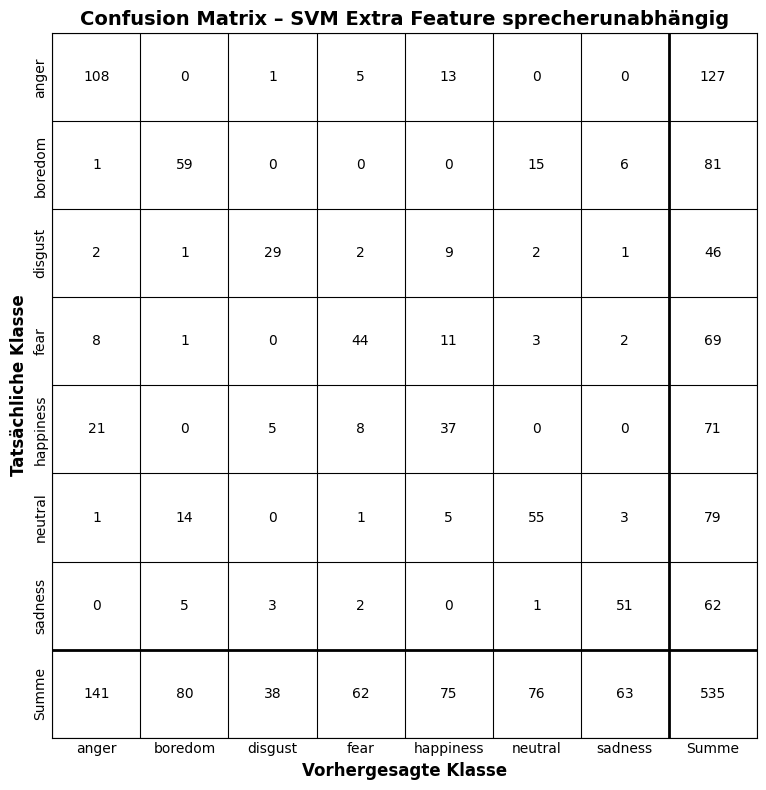

In [ ]:
# Confusion Matrix für Evaluation in BA
import matplotlib.pyplot as plt
import numpy as np

# Feste Reihenfolge der Klassen
labels = ["anger", "boredom", "disgust", "fear", "happiness", "neutral", "sadness"]

# Bereits aggregierte Confusion Matrix aus LOSO
conf_mat = conf_sum

# Summen berechnen
row_sums = conf_mat.sum(axis=1)
col_sums = conf_mat.sum(axis=0)
total_sum = conf_mat.sum()

# Erweiterte Matrix mit Summen
conf_mat_ext = np.zeros((len(labels) + 1, len(labels) + 1), dtype=int)
conf_mat_ext[:-1, :-1] = conf_mat
conf_mat_ext[:-1, -1] = row_sums
conf_mat_ext[-1, :-1] = col_sums
conf_mat_ext[-1, -1] = total_sum

# Erweiterte Labels
labels_ext = labels + ["Summe"]

# Plot
fig, ax = plt.subplots(figsize=(10, 8))

# Weißer Hintergrund
ax.imshow(np.ones_like(conf_mat_ext), cmap="gray", vmin=0, vmax=1)

# Hauptticks
ax.set_xticks(np.arange(len(labels_ext)))
ax.set_yticks(np.arange(len(labels_ext)))

# Beschriftungen
ax.set_xticklabels(labels_ext, rotation=0, ha="center")
ax.set_yticklabels(labels_ext, rotation=90, va="center")

# Zahlen ALLE normal
for i in range(conf_mat_ext.shape[0]):
    for j in range(conf_mat_ext.shape[1]):
        ax.text(
            j, i, str(conf_mat_ext[i, j]),
            ha="center", va="center",
            color="black",
            fontsize=10
        )

# Minor-Ticks für Gitterlinien
ax.set_xticks(np.arange(-0.5, len(labels_ext), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(labels_ext), 1), minor=True)

# Gitterlinien zeichnen
ax.grid(which="minor", color="black", linestyle='-', linewidth=0.8)

# Dickere Trennung vor Summenspalte und Summenzeile
n = len(labels_ext)
ax.axvline(x=n - 1.5, color="black", linewidth=2)
ax.axhline(y=n - 1.5, color="black", linewidth=2)

# Tick-Markierungen ausblenden
ax.tick_params(which="minor", bottom=False, left=False)
ax.tick_params(which="major", length=0)

# NUR Beschriftungen fett
ax.set_xlabel("Vorhergesagte Klasse", fontweight="bold", fontsize=12)
ax.set_ylabel("Tatsächliche Klasse", fontweight="bold", fontsize=12)
ax.set_title("Confusion Matrix – SVM Extra Feature sprecherunabhängig", fontweight="bold", fontsize=14)

plt.tight_layout()
plt.show()

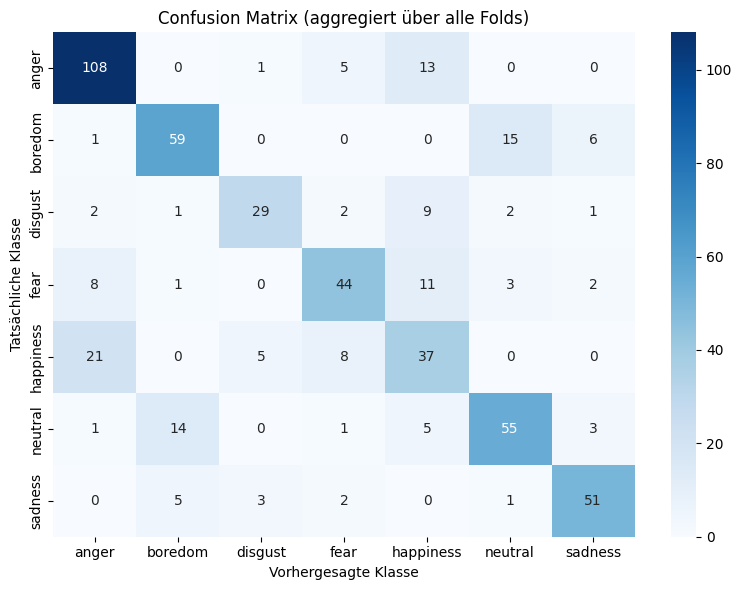

In [ ]:
#HeatMap
plt.figure(figsize=(8,6))
sns.heatmap(df_conf, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Vorhergesagte Klasse")
plt.ylabel("Tatsächliche Klasse")
plt.title("Confusion Matrix (aggregiert über alle Folds)")

plt.tight_layout()
plt.show()